# Notebook 01: Data Acquisition

**Cross-City Solar Irradiance Forecasting with Chronos-T5**

## Purpose
Fetch hourly solar irradiance and weather data from NASA POWER API for:
- **7 Training cities** covering India's climate diversity
- **5 Test cities** (unseen during training) for generalization evaluation

## City Selection Strategy
| Role | City | Climate Zone | Position |
|------|------|-------------|----------|
| Train | Jaipur | BWh (Hot desert) | NW corner |
| Train | Delhi | Cwa (Humid subtropical) | N center |
| Train | Guwahati | Cwa (Humid subtropical) | NE corner |
| Train | Ahmedabad | BSh (Hot semi-arid) | W coast |
| Train | Chennai | Aw (Tropical savanna) | SE coast |
| Train | Thiruvananthapuram | Am (Tropical monsoon) | S tip |
| Train | Nagpur | Aw (Tropical savanna) | Geographic center |
| Test | Hyderabad | BSh | Central-South |
| Test | Bangalore | Aw | South interior |
| Test | Kolkata | Aw | East coast |
| Test | Lucknow | Cwa | North plains |
| Test | Jodhpur | BWh | Desert interior |

In [3]:
import sys
import os
import pandas as pd
import numpy as np
from pathlib import Path

# Add project root to path
sys.path.insert(0, os.path.abspath('.'))

from utils.city_config import (
    CITY_METADATA, get_training_cities, get_test_cities, get_all_cities,
    NASA_POWER_VARIABLES, CONTEXT_LENGTH, FORECAST_HORIZON
)
from utils.data_utils import (
    fetch_nasa_power_data, fetch_all_cities, save_city_info_json,
    load_raw_data, generate_data_quality_report
)

print(f"Training cities ({len(get_training_cities())}): {get_training_cities()}")
print(f"Test cities ({len(get_test_cities())}): {get_test_cities()}")
print(f"Total: {len(get_all_cities())} cities")
print(f"\nNASA POWER variables ({len(NASA_POWER_VARIABLES)}): {NASA_POWER_VARIABLES}")

Training cities (7): ['jaipur', 'delhi', 'guwahati', 'ahmedabad', 'chennai', 'thiruvananthapuram', 'nagpur']
Test cities (5): ['hyderabad', 'bangalore', 'kolkata', 'lucknow', 'jodhpur']
Total: 12 cities

NASA POWER variables (13): ['ALLSKY_SFC_SW_DWN', 'CLRSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PRECTOTCORR', 'PS', 'WS10M', 'WD10M', 'CLOUD_AMT', 'ALLSKY_SFC_SW_DIFF', 'CLRSKY_SFC_SW_DIFF', 'ALLSKY_SFC_UV_INDEX', 'ALLSKY_SFC_PAR_TOT']


## 1. City Metadata Overview

In [4]:
# Display city metadata as a table
meta_df = pd.DataFrame(CITY_METADATA).T
meta_df.index.name = 'city'
display(meta_df[['state', 'latitude', 'longitude', 'elevation', 'climate_zone', 'is_coastal', 'role']])

,state,latitude,longitude,elevation,climate_zone,is_coastal,role
city,,,,,,,
jaipur,Rajasthan,26.9124,75.7873,431,BWh,False,train
delhi,NCT,28.7041,77.1025,216,Cwa,False,train
guwahati,Assam,26.1445,91.7362,55,Cwa,False,train
ahmedabad,Gujarat,23.0225,72.5714,53,BSh,False,train
chennai,Tamil Nadu,13.0827,80.2707,7,Aw,True,train
thiruvananthapuram,Kerala,8.5241,76.9366,10,Am,True,train
nagpur,Maharashtra,21.1458,79.0882,310,Aw,False,train
hyderabad,Telangana,17.385,78.4867,542,BSh,False,test
bangalore,Karnataka,12.9716,77.5946,920,Aw,False,test


In [5]:
# Save city metadata JSON
save_city_info_json('data/metadata/city_info.json')
print('City metadata saved.')

City metadata saved.


## 2. Fetch Training City Data

NASA POWER API: hourly data, 2013-01-01 to 2024-06-30 (~11.5 years).

The fetcher automatically:
- Chunks requests by year (API limit)
- Retries with exponential backoff on failures
- Resumes from checkpoint if interrupted
- Skips cities that already have cached CSVs

In [6]:
# Fetch TRAINING cities (skip already downloaded)
print("="*70)
print(" FETCHING TRAINING CITIES ")
print("="*70)

train_status = fetch_all_cities(
    cities=get_training_cities(),
    start_date='20130101',
    end_date='20240630',
    save_dir='data/raw',
    skip_existing=True,
)

print("\n" + "="*70)
print(" TRAINING CITY STATUS")
print("="*70)
for city, status in train_status.items():
    print(f"  {city:25s} -> {status}")

 FETCHING TRAINING CITIES 
  [jaipur] Already exists: jaipur_raw_2013_2024.csv — skipping

  Fetching: DELHI (NCT)
  Climate: Cwa, Lat: 28.7041, Lon: 77.1025


Fetching delhi: 100%|██████████| 12/12 [01:17<00:00,  6.46s/chunk]


  [delhi] Success: 100776 rows fetched

  Fetching: GUWAHATI (Assam)
  Climate: Cwa, Lat: 26.1445, Lon: 91.7362


Fetching guwahati: 100%|██████████| 12/12 [01:07<00:00,  5.65s/chunk]


  [guwahati] Success: 100776 rows fetched

  Fetching: AHMEDABAD (Gujarat)
  Climate: BSh, Lat: 23.0225, Lon: 72.5714


Fetching ahmedabad: 100%|██████████| 12/12 [01:12<00:00,  6.03s/chunk]


  [ahmedabad] Success: 100776 rows fetched
  [chennai] Already exists: chennai_raw_2013_2024.csv — skipping

  Fetching: THIRUVANANTHAPURAM (Kerala)
  Climate: Am, Lat: 8.5241, Lon: 76.9366


Fetching thiruvananthapuram: 100%|██████████| 12/12 [01:15<00:00,  6.31s/chunk]


  [thiruvananthapuram] Success: 100776 rows fetched

  Fetching: NAGPUR (Maharashtra)
  Climate: Aw, Lat: 21.1458, Lon: 79.0882


Fetching nagpur: 100%|██████████| 12/12 [01:11<00:00,  6.00s/chunk]


  [nagpur] Success: 100776 rows fetched

 TRAINING CITY STATUS
  jaipur                    -> skipped
  delhi                     -> fetched
  guwahati                  -> fetched
  ahmedabad                 -> fetched
  chennai                   -> skipped
  thiruvananthapuram        -> fetched
  nagpur                    -> fetched


## 3. Fetch Test City Data (Unseen)

In [7]:
# Fetch TEST cities (into separate folder to avoid leakage)
print("="*70)
print(" FETCHING TEST (UNSEEN) CITIES ")
print("="*70)

test_status = fetch_all_cities(
    cities=get_test_cities(),
    start_date='20130101',
    end_date='20240630',
    save_dir='data/raw_unseen',
    skip_existing=True,
)

print("\n" + "="*70)
print(" TEST CITY STATUS")
print("="*70)
for city, status in test_status.items():
    print(f"  {city:25s} -> {status}")

 FETCHING TEST (UNSEEN) CITIES 

  Fetching: HYDERABAD (Telangana)
  Climate: BSh, Lat: 17.385, Lon: 78.4867


Fetching hyderabad: 100%|██████████| 12/12 [01:12<00:00,  6.00s/chunk]


  [hyderabad] Success: 100776 rows fetched

  Fetching: BANGALORE (Karnataka)
  Climate: Aw, Lat: 12.9716, Lon: 77.5946


Fetching bangalore: 100%|██████████| 12/12 [01:06<00:00,  5.58s/chunk]


  [bangalore] Success: 100776 rows fetched

  Fetching: KOLKATA (West Bengal)
  Climate: Aw, Lat: 22.5726, Lon: 88.3639


Fetching kolkata: 100%|██████████| 12/12 [01:11<00:00,  5.96s/chunk]


  [kolkata] Success: 100776 rows fetched

  Fetching: LUCKNOW (Uttar Pradesh)
  Climate: Cwa, Lat: 26.8467, Lon: 80.9462


Fetching lucknow: 100%|██████████| 12/12 [01:16<00:00,  6.39s/chunk]


  [lucknow] Success: 100776 rows fetched

  Fetching: JODHPUR (Rajasthan)
  Climate: BWh, Lat: 26.2389, Lon: 73.0243


Fetching jodhpur: 100%|██████████| 12/12 [01:13<00:00,  6.12s/chunk]


  [jodhpur] Success: 100776 rows fetched

 TEST CITY STATUS
  hyderabad                 -> fetched
  bangalore                 -> fetched
  kolkata                   -> fetched
  lucknow                   -> fetched
  jodhpur                   -> fetched


## 4. Data Quality Report

In [8]:
# Load and inspect all downloaded data
import json

all_reports = {}
summary_rows = []

for city in get_all_cities():
    # Try both directories
    df = None
    for d in ['data/raw', 'data/raw_unseen']:
        for f in Path(d).glob(f'{city}_raw_*.csv'):
            df = pd.read_csv(f, parse_dates=['timestamp'])
            break
        if df is not None:
            break
    
    if df is None:
        print(f"  WARNING: No data found for {city}")
        continue
    
    info = CITY_METADATA[city]
    n_rows = len(df)
    date_range = f"{df['timestamp'].min().date()} to {df['timestamp'].max().date()}"
    ghi_col = 'ALLSKY_SFC_SW_DWN'
    missing_pct = df[ghi_col].isna().mean() * 100 if ghi_col in df.columns else -1
    ghi_mean = df[ghi_col].mean() if ghi_col in df.columns else 0
    
    summary_rows.append({
        'City': city.title(),
        'Role': 'Train' if info['role'] == 'train' else 'Test',
        'Climate': info['climate_zone'],
        'Rows': n_rows,
        'Date Range': date_range,
        'GHI Missing %': f'{missing_pct:.2f}',
        'Mean GHI': f'{ghi_mean:.1f}',
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

print(f"\nTotal rows across all cities: {summary_df['Rows'].sum():,}")

,City,Role,Climate,Rows,Date Range,GHI Missing %,Mean GHI
0,Jaipur,Train,BWh,92016,2014-01-01 to 2024-07-01,0.00,220.1
1,Delhi,Train,Cwa,100776,2013-01-01 to 2024-07-01,0.00,200.1
2,Guwahati,Train,Cwa,100776,2013-01-01 to 2024-07-01,0.00,181.7
3,Ahmedabad,Train,BSh,100776,2013-01-01 to 2024-07-01,0.00,225.8
4,Chennai,Train,Aw,100776,2013-01-01 to 2024-07-01,0.00,215.1
5,Thiruvananthapuram,Train,Am,100776,2013-01-01 to 2024-07-01,0.00,223.6
6,Nagpur,Train,Aw,100776,2013-01-01 to 2024-07-01,0.00,210.1
7,Hyderabad,Test,BSh,100776,2013-01-01 to 2024-07-01,0.00,216.3
8,Bangalore,Test,Aw,100776,2013-01-01 to 2024-07-01,0.00,225.0
9,Kolkata,Test,Aw,100776,2013-01-01 to 2024-07-01,0.00,185.8



Total rows across all cities: 1,200,552


In [9]:
# Generate and save detailed quality reports
for city in get_training_cities():
    for f in Path('data/raw').glob(f'{city}_raw_*.csv'):
        df = pd.read_csv(f, parse_dates=['timestamp'])
        report = generate_data_quality_report(df, city)
        all_reports[city] = report

for city in get_test_cities():
    for f in Path('data/raw_unseen').glob(f'{city}_raw_*.csv'):
        df = pd.read_csv(f, parse_dates=['timestamp'])
        report = generate_data_quality_report(df, city)
        all_reports[city] = report

# Save reports
os.makedirs('results', exist_ok=True)
with open('results/data_quality_reports.json', 'w') as f:
    json.dump(all_reports, f, indent=2, default=str)

print(f"Quality reports saved for {len(all_reports)} cities.")

Quality reports saved for 12 cities.


## 5. Quick Visualization — GHI Distribution by City

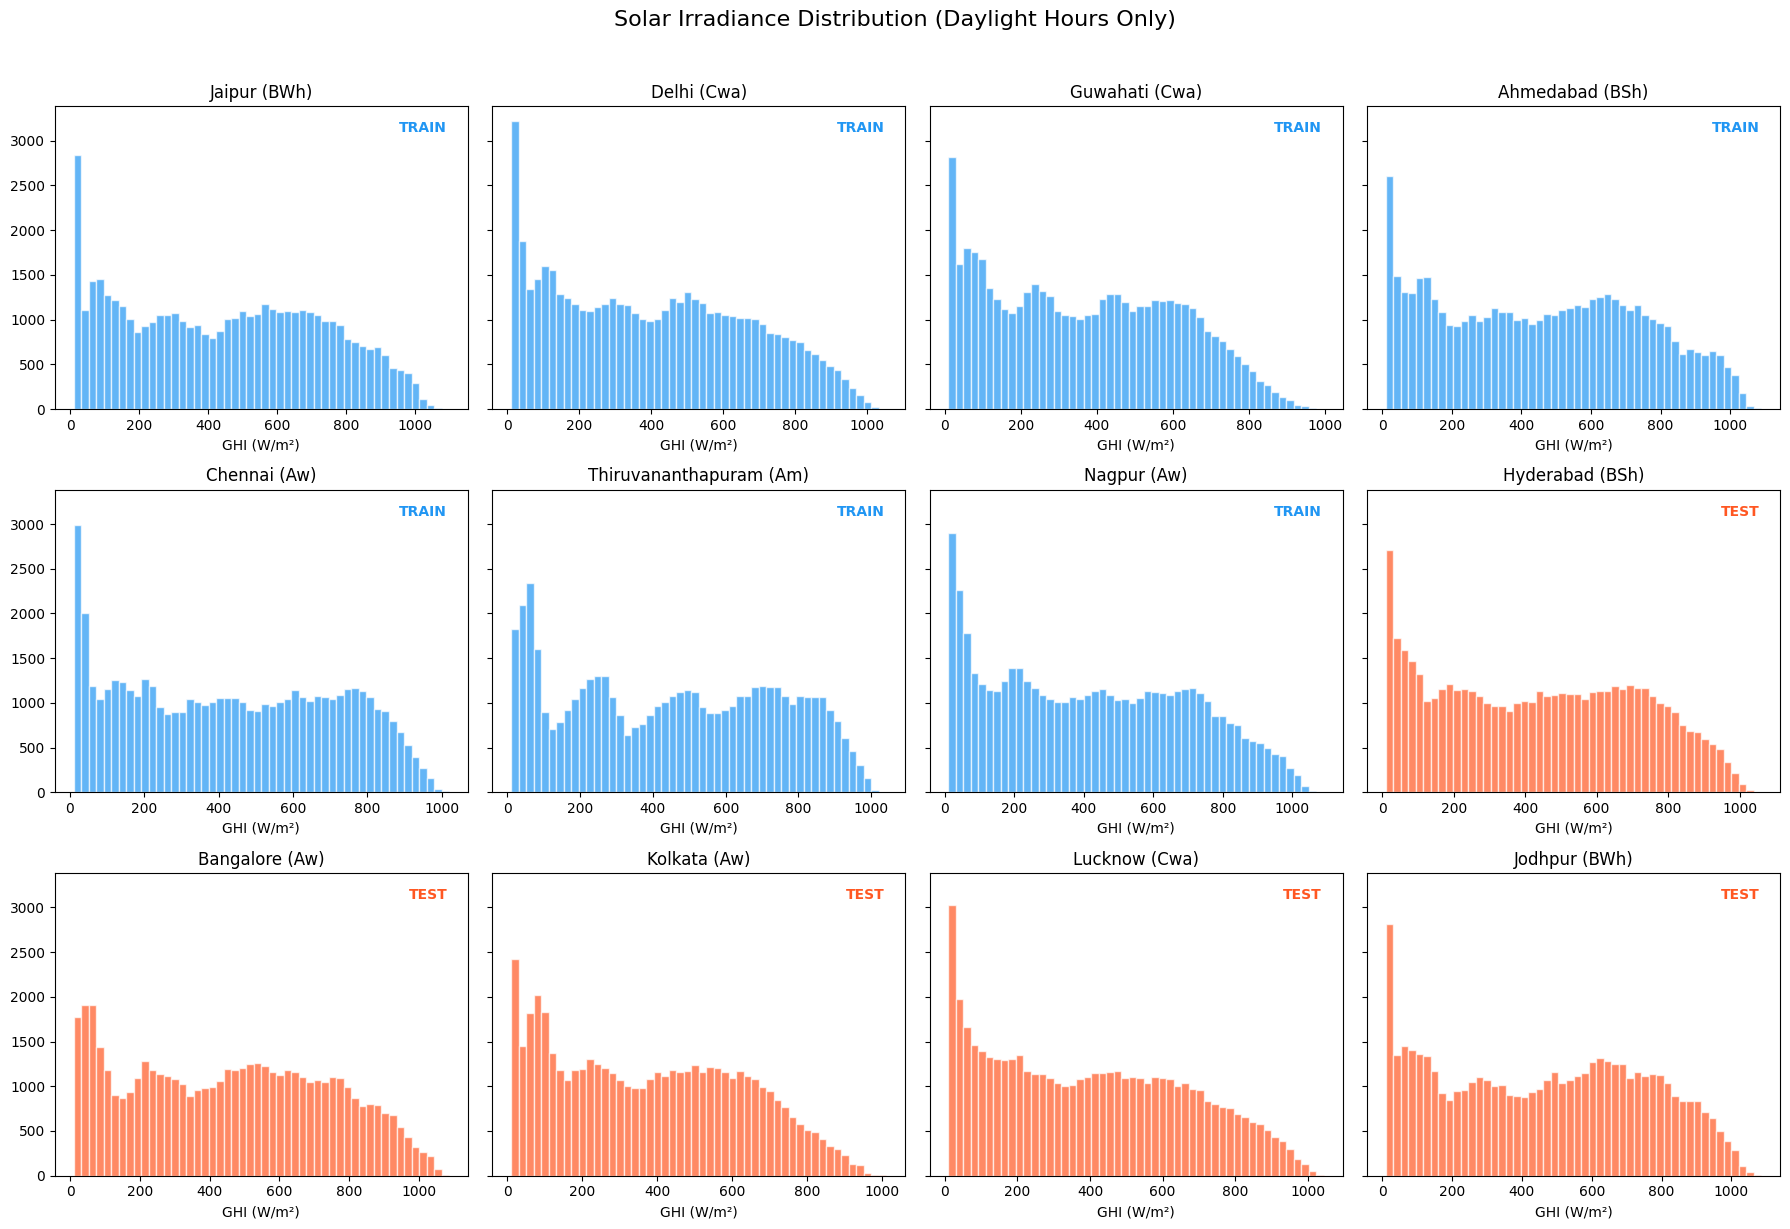

Figure saved: results/figures/01_ghi_distributions.png


In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharey=True)
axes = axes.flatten()

for idx, city in enumerate(get_all_cities()):
    df = None
    for d in ['data/raw', 'data/raw_unseen']:
        for f in Path(d).glob(f'{city}_raw_*.csv'):
            df = pd.read_csv(f, parse_dates=['timestamp'])
            break
        if df is not None:
            break
    
    if df is None or idx >= len(axes):
        continue
    
    ax = axes[idx]
    ghi = df['ALLSKY_SFC_SW_DWN'].dropna()
    daylight = ghi[ghi > 10]
    
    info = CITY_METADATA[city]
    color = '#2196F3' if info['role'] == 'train' else '#FF5722'
    
    ax.hist(daylight, bins=50, alpha=0.7, color=color, edgecolor='white')
    ax.set_title(f"{city.title()} ({info['climate_zone']})")
    ax.set_xlabel('GHI (W/m²)')
    role = 'TRAIN' if info['role'] == 'train' else 'TEST'
    ax.text(0.95, 0.95, role, transform=ax.transAxes, ha='right', va='top',
            fontweight='bold', color=color, fontsize=10)

plt.suptitle('Solar Irradiance Distribution (Daylight Hours Only)', fontsize=16, y=1.02)
plt.tight_layout()
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/01_ghi_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: results/figures/01_ghi_distributions.png')

## Summary

**Data acquired:**
- 7 training cities × ~100K hours = ~700K+ hourly records
- 5 test cities × ~100K hours = ~500K+ hourly records  
- 13 meteorological variables per hour
- Date range: 2013-01-01 to 2024-06-30

**Next:** Notebook 02 — Preprocessing & Feature Engineering